In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn joblib streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 48.5 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

import joblib

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os

os.listdir('/content/drive/MyDrive')

['Getting started.pdf',
 'pranavcast.pdf',
 'pranav2.pdf',
 'ust.odt',
 'ust (2).gdoc',
 'ust (1).gdoc',
 'ust.gdoc',
 'image.png',
 'Application for registration for examination - 3 pages.gdoc',
 'attachment.pdf',
 '1226.pdf',
 '3.jpg',
 'Pranav NV.doc',
 'PRANAV_CV (2).pdf',
 '2.jpg',
 'pranav_RES.docx',
 'PRANAV_CV (1).doc',
 'PRANAV_CV.doc',
 'PRANAV_CV (1).gdoc',
 'PRANAV_CV.gdoc',
 'pranav_RES.gdoc',
 'RH254.gdoc',
 'Classroom',
 'Module-01.gdoc',
 'Module-04.gdoc',
 'tji-ovrj-kst - Mar 21, 2022.pdf',
 'Pranav_resume2023 (4).pdf',
 'E094C03B-391F-45C8-B56F-02242AA92DBA.jpeg',
 'Pranav_NV_CV (1) (2) (1) (1) (1).docx',
 'test plan .docx',
 'Colab Notebooks',
 'Assignments',
 ' DS | DS09 | FEB| Academic Sheet | ML .gsheet',
 'restaurant_recommender',
 'zomato.csv (2).zip',
 'zomato.csv']

In [10]:
file_path = "/content/drive/MyDrive/zomato.csv"

df = pd.read_csv(file_path)

df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [11]:
print("Shape:", df.shape)

Shape: (51717, 17)


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   url                          51717 non-null  object
 1   address                      51717 non-null  object
 2   name                         51717 non-null  object
 3   online_order                 51717 non-null  object
 4   book_table                   51717 non-null  object
 5   rate                         43942 non-null  object
 6   votes                        51717 non-null  int64 
 7   phone                        50509 non-null  object
 8   location                     51696 non-null  object
 9   rest_type                    51490 non-null  object
 10  dish_liked                   23639 non-null  object
 11  cuisines                     51672 non-null  object
 12  approx_cost(for two people)  51371 non-null  object
 13  reviews_list                 51

In [13]:
df.columns

Index(['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes',
       'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='object')

In [14]:
df.isnull().sum()

,0
url,0
address,0
name,0
online_order,0
book_table,0
rate,7775
votes,0
phone,1208
location,21
rest_type,227


In [15]:
df.isnull().sum()

,0
url,0
address,0
name,0
online_order,0
book_table,0
rate,7775
votes,0
phone,1208
location,21
rest_type,227


In [16]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [17]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
url,51717,51717,https://www.zomato.com/bangalore/the-nest-the-...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
address,51717,11495,Delivery Only,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,51717,8792,Cafe Coffee Day,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
online_order,51717,2,Yes,30444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
book_table,51717,2,No,45268,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rate,43942,64,NEW,2208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
votes,51717.0,NaN,NaN,NaN,283.697527,803.838853,0.0,7.0,41.0,198.0,16832.0
phone,50509,14926,080 43334321,216,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,51696,93,BTM,5124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rest_type,51490,93,Quick Bites,19132,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
drop_columns = [
    'url',
    'phone',
    'address',
    'menu_item',
    'reviews_list'
]

df = df.drop(
    columns=[col for col in drop_columns if col in df.columns]
)

In [19]:
df.head()

,name,online_order,book_table,rate,votes,location,rest_type,dish_liked,cuisines,approx_cost(for two people),listed_in(type),listed_in(city)
0,Jalsa,Yes,Yes,4.1/5,775,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1/5,787,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8/5,918,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,Buffet,Banashankari
4,Grand Village,No,No,3.8/5,166,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,Buffet,Banashankari


In [20]:
df['name'] = df['name'].astype(str).str.strip()

In [21]:
df = df[
    df['name'].notna() &
    (df['name'].str.strip() != '')
]

In [22]:
df['rate'] = (
    df['rate']
    .astype(str)
    .str.replace('/5', '', regex=False)
)

In [23]:
df['rate'] = pd.to_numeric(
    df['rate'],
    errors='coerce'
)

In [24]:
df['rate'].describe()

,rate
count,41665.000000
mean,3.700449
std,0.440513
min,1.800000
25%,3.400000
50%,3.700000
75%,4.000000
max,4.900000


In [27]:
print(df.columns.tolist())

['name', 'online_order', 'book_table', 'rate', 'votes', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'listed_in(type)', 'listed_in(city)']


In [28]:
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print(df.columns.tolist())

['name', 'online_order', 'book_table', 'rate', 'votes', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for_two_people)', 'listed_in(type)', 'listed_in(city)']


In [30]:
df = df.rename(columns={
    'approx_cost(for_two_people)': 'cost_for_two'
})

In [38]:
df = df.rename(columns={
    'rest_type': 'restaurant_type'
})

In [31]:
df['cost_for_two'] = (
    df['cost_for_two']
    .astype(str)
    .str.replace(',', '', regex=False)
)

In [33]:
df['cost_for_two'] = pd.to_numeric(
    df['cost_for_two'],
    errors='coerce'
)

In [34]:
df['cost_for_two'].describe()

,cost_for_two
count,51371.000000
mean,555.431566
std,438.850728
min,40.000000
25%,300.000000
50%,400.000000
75%,650.000000
max,6000.000000


In [35]:
df['votes'] = pd.to_numeric(
    df['votes'],
    errors='coerce'
)

In [36]:
df['votes'] = df['votes'].fillna(0)

In [39]:
important_columns = [
    'name',
    'location',
    'rate',
    'votes',
    'restaurant_type',
    'cuisines',
    'cost_for_two'
]

df[important_columns].isnull().sum()

,0
name,0
location,21
rate,10052
votes,0
restaurant_type,227
cuisines,45
cost_for_two,346


In [40]:
text_columns = [
    'location',
    'restaurant_type',
    'cuisines',
    'dish_liked',
    'listed_type',
    'listed_city'
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].fillna('')

In [41]:
df['rate'] = df['rate'].fillna(df['rate'].median())

In [42]:
df['cost_for_two'] = df['cost_for_two'].fillna(
    df['cost_for_two'].median()
)

In [43]:
df[['name', 'location']].duplicated().sum()

np.int64(39566)

In [44]:
df = df.drop_duplicates(
    subset=['name', 'location']
).reset_index(drop=True)

In [45]:
print("New shape:", df.shape)

New shape: (12151, 12)


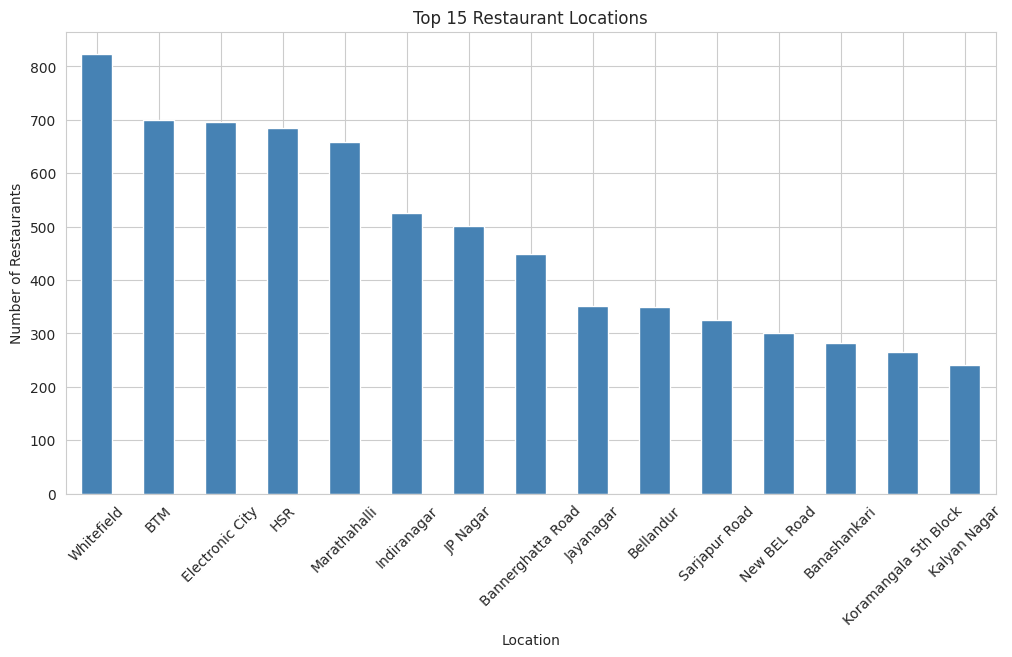

In [46]:
plt.figure(figsize=(12,6))

df['location'].value_counts().head(15).plot(
    kind='bar',
    color='steelblue'
)

plt.title("Top 15 Restaurant Locations")
plt.xlabel("Location")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)
plt.show()

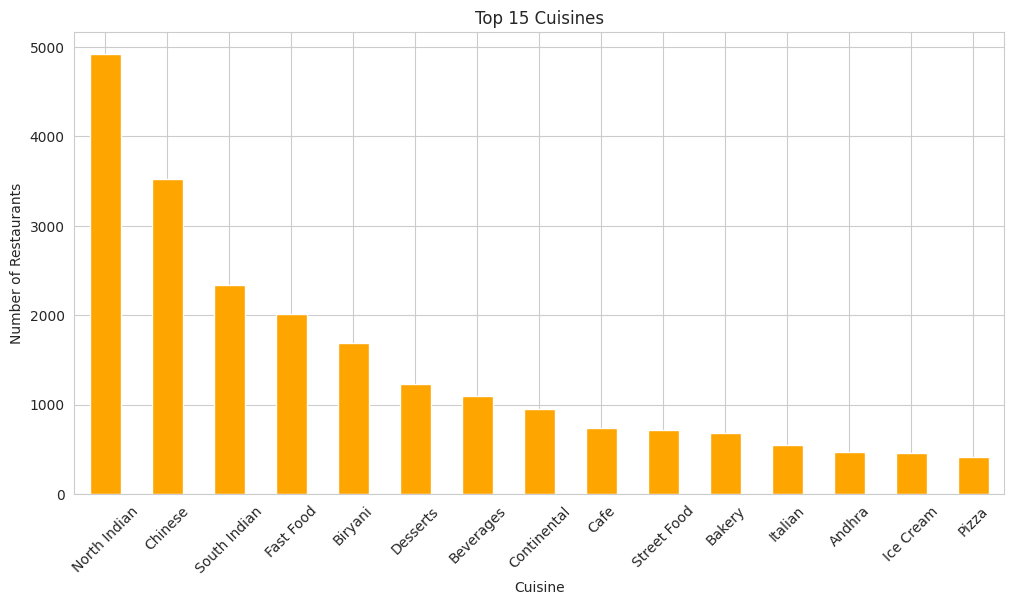

In [47]:
cuisine_counts = (
    df['cuisines']
    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12,6))

cuisine_counts.plot(
    kind='bar',
    color='orange'
)

plt.title("Top 15 Cuisines")
plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)
plt.show()

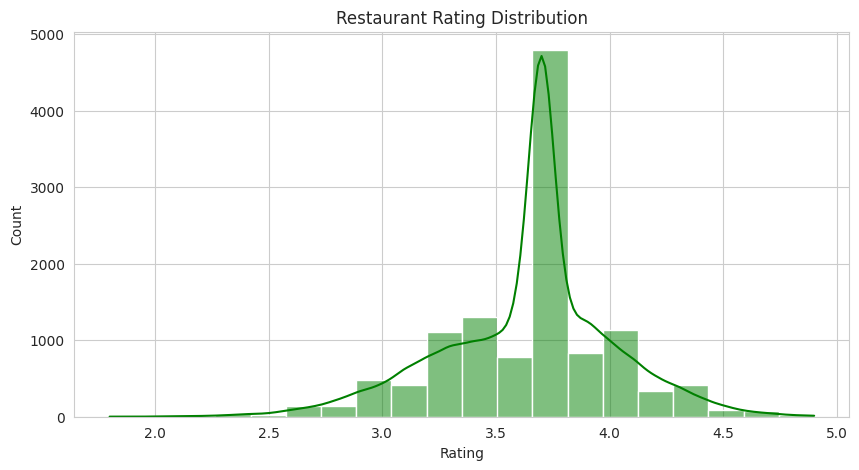

In [48]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['rate'],
    bins=20,
    kde=True,
    color='green'
)

plt.title("Restaurant Rating Distribution")
plt.xlabel("Rating")
plt.show()

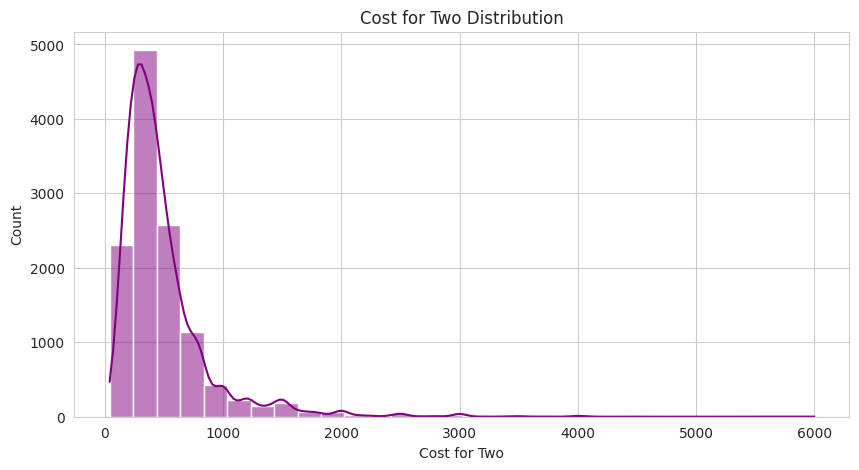

In [49]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['cost_for_two'],
    bins=30,
    kde=True,
    color='purple'
)

plt.title("Cost for Two Distribution")
plt.xlabel("Cost for Two")
plt.show()

In [51]:
df = df[
    df['cost_for_two'] > 0
]

In [52]:
df = df.reset_index(drop=True)

In [54]:
print(df.columns.tolist())


['name', 'online_order', 'book_table', 'rate', 'votes', 'location', 'restaurant_type', 'dish_liked', 'cuisines', 'cost_for_two', 'listed_in(type)', 'listed_in(city)']


In [55]:
df = df.rename(columns={
    'listed_in(type)': 'listed_in_type',
    'listed_in(city)': 'listed_in_city'
})

print(df.columns.tolist())

['name', 'online_order', 'book_table', 'rate', 'votes', 'location', 'restaurant_type', 'dish_liked', 'cuisines', 'cost_for_two', 'listed_in_type', 'listed_in_city']


In [57]:
df['combined_features'] = (
    df['location'].fillna('') + ' ' +
    df['restaurant_type'].fillna('') + ' ' +
    df['cuisines'].fillna('') + ' ' +
    df['dish_liked'].fillna('') + ' ' +
    df['listed_in_type'].fillna('')
)

In [58]:
df[
    ['name', 'combined_features']
].head()

,name,combined_features
0,Jalsa,"Banashankari Casual Dining North Indian, Mughl..."
1,Spice Elephant,"Banashankari Casual Dining Chinese, North Indi..."
2,San Churro Cafe,"Banashankari Cafe, Casual Dining Cafe, Mexican..."
3,Addhuri Udupi Bhojana,"Banashankari Quick Bites South Indian, North I..."
4,Grand Village,"Basavanagudi Casual Dining North Indian, Rajas..."


In [59]:
df['combined_features'] = (
    df['combined_features']
    .str.lower()
    .str.replace(',', ' ', regex=False)
)

In [60]:
df['combined_features'] = (
    df['combined_features']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

In [61]:
#TF-IDF Vectorization

tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    max_features=50000
)

In [62]:
tfidf_matrix = tfidf.fit_transform(
    df['combined_features']
)

In [63]:
print(tfidf_matrix.shape)

(12151, 17809)


In [64]:
#Calculate Cosine Similarity

cosine_sim = cosine_similarity(
    tfidf_matrix
)

In [65]:
print(cosine_sim.shape)

(12151, 12151)


In [66]:
restaurant_indices = pd.Series(
    df.index,
    index=df['name'].str.lower()
).drop_duplicates()

In [70]:
import numpy as np
import pandas as pd

def recommend_similar_restaurants(restaurant_name, top_n=10):

    # Find restaurant
    matches = df[
        df['name'].astype(str).str.lower().str.strip()
        == restaurant_name.lower().strip()
    ]

    if matches.empty:
        print(f"Restaurant not found: {restaurant_name}")
        return pd.DataFrame()

    # Get DataFrame index
    idx = matches.index[0]

    # Get similarity scores for this restaurant
    similarity_scores = np.asarray(
        cosine_sim[idx]
    ).flatten()

    # Get indices sorted by similarity
    similar_indices = np.argsort(
        similarity_scores
    )[::-1]

    # Remove the restaurant itself
    similar_indices = [
        i for i in similar_indices
        if i != idx
    ]

    # Take top N
    similar_indices = similar_indices[:top_n]

    # Create recommendations
    recommendations = df.iloc[
        similar_indices
    ][[
        'name',
        'location',
        'restaurant_type',
        'cuisines',
        'rate',
        'votes',
        'cost_for_two'
    ]].copy()

    # Add similarity score
    recommendations['similarity_score'] = [
        similarity_scores[i]
        for i in similar_indices
    ]

    return recommendations.reset_index(drop=True)

In [71]:
recommend_similar_restaurants(
    "Meghana Foods",
    10
)

,name,location,restaurant_type,cuisines,rate,votes,cost_for_two,similarity_score
0,Biriyani Bungalow,Sarjapur Road,Casual Dining,"Biryani, North Indian, Chinese",3.9,222,800.0,0.620533
1,Aroma's Hyderabad House,Nagawara,Casual Dining,"Mughlai, Biryani, North Indian",4.2,533,800.0,0.592476
2,Hyderabad Biryaani House,Old Airport Road,Casual Dining,"Biryani, North Indian, Chinese",3.9,1615,550.0,0.580947
3,Meghana Foods,Indiranagar,Casual Dining,"Biryani, Chinese, North Indian, Seafood",4.2,1746,750.0,0.541412
4,Hyderabad Biryaani House,Whitefield,Casual Dining,"Biryani, North Indian, Chinese",3.5,374,550.0,0.540595
5,Mani's Dum Biryani,JP Nagar,Casual Dining,"Biryani, Kebab",4.2,373,750.0,0.529630
6,Hyderabad Biryaani House,Marathahalli,Casual Dining,"Biryani, North Indian, Chinese",3.7,833,550.0,0.528033
7,Meghana Biryani,Bellandur,Casual Dining,North Indian,2.3,235,800.0,0.523776
8,Biryani Day,Marathahalli,Casual Dining,"North Indian, Chinese, Biryani, Andhra",3.7,751,500.0,0.523016
9,Mani's Dum Biryani,Koramangala 1st Block,Casual Dining,"Biryani, Kebab",3.9,374,750.0,0.521745


In [72]:
df['popularity_score'] = np.log1p(
    df['votes']
)

In [73]:
scaler = MinMaxScaler()

df['popularity_score'] = scaler.fit_transform(
    df[['popularity_score']]
)

In [74]:
df['rating_score'] = df['rate'] / 5

In [75]:
df[
    ['name', 'rate', 'votes',
     'rating_score', 'popularity_score']
].head()

,name,rate,votes,rating_score,popularity_score
0,Jalsa,4.1,775,0.82,0.685872
1,Spice Elephant,4.1,787,0.82,0.687454
2,San Churro Cafe,3.8,918,0.76,0.703306
3,Addhuri Udupi Bhojana,3.7,88,0.74,0.462663
4,Grand Village,3.8,166,0.76,0.527534


In [79]:
import numpy as np
import pandas as pd

def hybrid_recommendation(restaurant_name, top_n=10):

    # Find all matching restaurants
    matches = df[
        df['name'].astype(str).str.lower().str.strip()
        == restaurant_name.lower().strip()
    ]

    if matches.empty:
        print(f"Restaurant not found: {restaurant_name}")
        return pd.DataFrame()

    # Use the first matching restaurant
    idx = matches.index[0]

    # Make sure idx is a single integer
    idx = int(idx)

    # Get content similarity scores
    content_scores = np.asarray(
        cosine_sim[idx]
    ).flatten()

    # Create candidate indices
    candidate_indices = np.arange(len(df))

    # Remove the selected restaurant
    candidate_indices = candidate_indices[
        candidate_indices != idx
    ]

    # Normalize content scores
    content_min = content_scores.min()
    content_max = content_scores.max()

    if content_max > content_min:
        content_normalized = (
            content_scores - content_min
        ) / (
            content_max - content_min
        )
    else:
        content_normalized = np.zeros_like(
            content_scores
        )

    # Create final scores
    final_scores = content_normalized.copy()

    # Get top candidates
    top_indices = candidate_indices[
        np.argsort(
            final_scores[candidate_indices]
        )[::-1][:top_n]
    ]

    # Create result
    recommendations = df.iloc[
        top_indices
    ][[
        'name',
        'location',
        'restaurant_type',
        'cuisines',
        'rate',
        'votes',
        'cost_for_two'
    ]].copy()

    recommendations['content_score'] = [
        content_scores[i]
        for i in top_indices
    ]

    recommendations['hybrid_score'] = [
        final_scores[i]
        for i in top_indices
    ]

    return recommendations.reset_index(drop=True)

In [80]:
hybrid_recommendation(
    "Meghana Foods",
    10
)

,name,location,restaurant_type,cuisines,rate,votes,cost_for_two,content_score,hybrid_score
0,Biriyani Bungalow,Sarjapur Road,Casual Dining,"Biryani, North Indian, Chinese",3.9,222,800.0,0.620533,0.620533
1,Aroma's Hyderabad House,Nagawara,Casual Dining,"Mughlai, Biryani, North Indian",4.2,533,800.0,0.592476,0.592476
2,Hyderabad Biryaani House,Old Airport Road,Casual Dining,"Biryani, North Indian, Chinese",3.9,1615,550.0,0.580947,0.580947
3,Meghana Foods,Indiranagar,Casual Dining,"Biryani, Chinese, North Indian, Seafood",4.2,1746,750.0,0.541412,0.541412
4,Hyderabad Biryaani House,Whitefield,Casual Dining,"Biryani, North Indian, Chinese",3.5,374,550.0,0.540595,0.540595
5,Mani's Dum Biryani,JP Nagar,Casual Dining,"Biryani, Kebab",4.2,373,750.0,0.529630,0.529630
6,Hyderabad Biryaani House,Marathahalli,Casual Dining,"Biryani, North Indian, Chinese",3.7,833,550.0,0.528033,0.528033
7,Meghana Biryani,Bellandur,Casual Dining,North Indian,2.3,235,800.0,0.523776,0.523776
8,Biryani Day,Marathahalli,Casual Dining,"North Indian, Chinese, Biryani, Andhra",3.7,751,500.0,0.523016,0.523016
9,Mani's Dum Biryani,Koramangala 1st Block,Casual Dining,"Biryani, Kebab",3.9,374,750.0,0.521745,0.521745


In [81]:
result = hybrid_recommendation(
    "Meghana Foods",
    10
)

result

,name,location,restaurant_type,cuisines,rate,votes,cost_for_two,content_score,hybrid_score
0,Biriyani Bungalow,Sarjapur Road,Casual Dining,"Biryani, North Indian, Chinese",3.9,222,800.0,0.620533,0.620533
1,Aroma's Hyderabad House,Nagawara,Casual Dining,"Mughlai, Biryani, North Indian",4.2,533,800.0,0.592476,0.592476
2,Hyderabad Biryaani House,Old Airport Road,Casual Dining,"Biryani, North Indian, Chinese",3.9,1615,550.0,0.580947,0.580947
3,Meghana Foods,Indiranagar,Casual Dining,"Biryani, Chinese, North Indian, Seafood",4.2,1746,750.0,0.541412,0.541412
4,Hyderabad Biryaani House,Whitefield,Casual Dining,"Biryani, North Indian, Chinese",3.5,374,550.0,0.540595,0.540595
5,Mani's Dum Biryani,JP Nagar,Casual Dining,"Biryani, Kebab",4.2,373,750.0,0.529630,0.529630
6,Hyderabad Biryaani House,Marathahalli,Casual Dining,"Biryani, North Indian, Chinese",3.7,833,550.0,0.528033,0.528033
7,Meghana Biryani,Bellandur,Casual Dining,North Indian,2.3,235,800.0,0.523776,0.523776
8,Biryani Day,Marathahalli,Casual Dining,"North Indian, Chinese, Biryani, Andhra",3.7,751,500.0,0.523016,0.523016
9,Mani's Dum Biryani,Koramangala 1st Block,Casual Dining,"Biryani, Kebab",3.9,374,750.0,0.521745,0.521745


In [82]:
def recommend_by_preferences(
    location=None,
    cuisine=None,
    max_budget=None,
    min_rating=0,
    online_order=None,
    restaurant_type=None,
    top_n=10
):

    result = df.copy()

    # Location
    if location:
        result = result[
            result['location']
            .str.contains(
                location,
                case=False,
                na=False
            )
        ]

    # Cuisine
    if cuisine:
        result = result[
            result['cuisines']
            .str.contains(
                cuisine,
                case=False,
                na=False
            )
        ]

    # Budget
    if max_budget:
        result = result[
            result['cost_for_two'] <= max_budget
        ]

    # Rating
    result = result[
        result['rate'] >= min_rating
    ]

    # Online order
    if online_order:
        result = result[
            result['online_order']
            .str.lower()
            .eq(online_order.lower())
        ]

    # Restaurant type
    if restaurant_type:
        result = result[
            result['restaurant_type']
            .str.contains(
                restaurant_type,
                case=False,
                na=False
            )
        ]

    result = result.sort_values(
        by=[
            'rate',
            'popularity_score'
        ],
        ascending=False
    )

    return result.head(top_n)

In [83]:
recommend_by_preferences(
    location="Koramangala",
    cuisine="North Indian",
    max_budget=800,
    min_rating=4,
    top_n=10
)

,name,online_order,book_table,rate,votes,location,restaurant_type,dish_liked,cuisines,cost_for_two,listed_in_type,listed_in_city,combined_features,popularity_score,rating_score
6126,ECHOES Koramangala,No,No,4.7,3197,Koramangala 5th Block,"Cafe, Casual Dining","Pasta, Momos, Mezze Platter, Pizza, Waffles, C...","Chinese, American, Continental, Italian, North...",750.0,Dine-out,BTM,koramangala 5th block cafe casual dining chine...,0.831839,0.94
1668,eat.fit,Yes,No,4.6,143,Koramangala 5th Block,Delivery,"Brownie, Noodles","Healthy Food, North Indian, Biryani, Continent...",500.0,Delivery,Basavanagudi,koramangala 5th block delivery healthy food no...,0.512260,0.92
9580,Wild Thyme Restaurant,No,No,4.5,42,Koramangala 5th Block,Casual Dining,,"Chinese, Continental, North Indian, Italian, S...",800.0,Delivery,Koramangala 4th Block,koramangala 5th block casual dining chinese co...,0.387683,0.90
5186,Meghana Foods,Yes,No,4.4,7210,Koramangala 5th Block,Casual Dining,"Chicken Boneless Biryani, Egg Curry, Andhra Bi...","Biryani, Seafood, Andhra, North Indian",600.0,Delivery,BTM,koramangala 5th block casual dining biryani se...,0.915647,0.88
9757,BOX8- Desi Meals,Yes,No,4.4,405,Koramangala 5th Block,"Takeaway, Delivery","Paratha, Dal Makhani, Biryani, Gulab Jamun, Sa...","North Indian, Mughlai, Fast Food",500.0,Delivery,Koramangala 5th Block,koramangala 5th block takeaway delivery north ...,0.619101,0.88
5005,Zee5 Loft,Yes,No,4.4,351,Koramangala 6th Block,Cafe,"Tomato Soup, Salad, Pizza, Brownie Shake, Chic...","Cafe, North Indian, Pizza, Sandwich, Salad",500.0,Delivery,BTM,koramangala 6th block cafe cafe north indian p...,0.604390,0.88
5076,Aligarh House,Yes,No,4.4,98,Koramangala,Delivery,"Raita, Muradabadi Biryani","North Indian, Biryani, Awadhi, Mughlai",400.0,Delivery,BTM,koramangala delivery north indian biryani awad...,0.473639,0.88
4929,Kota Kachori,Yes,No,4.3,3605,Koramangala 6th Block,Quick Bites,"Pyaz Kachori, Chaat, Gajar Ka Halwa, Shrikhand...","Street Food, Desserts, North Indian, Mithai, R...",400.0,Delivery,BTM,koramangala 6th block quick bites street food ...,0.844215,0.86
5339,Gramin,Yes,No,4.3,3447,Koramangala 7th Block,Casual Dining,"Chaach, Bhindi Anardana, Thandai, Jal-jeera, L...",North Indian,600.0,Delivery,BTM,koramangala 7th block casual dining north indi...,0.839597,0.86
5752,Nagarjuna,No,No,4.3,2296,Koramangala 5th Block,Casual Dining,"Andhra Meal, Chicken Pepper Dry, Andhra Thali,...","Andhra, North Indian, Biryani",800.0,Delivery,BTM,koramangala 5th block casual dining andhra nor...,0.797729,0.86


In [84]:
#final recommendation fn

def recommend_restaurants(
    location="",
    cuisine="",
    max_budget=None,
    min_rating=0,
    restaurant_type="",
    top_n=10
):

    result = df.copy()

    if location:
        result = result[
            result['location']
            .str.contains(
                location,
                case=False,
                na=False
            )
        ]

    if cuisine:
        result = result[
            result['cuisines']
            .str.contains(
                cuisine,
                case=False,
                na=False
            )
        ]

    if max_budget:
        result = result[
            result['cost_for_two'] <= max_budget
        ]

    result = result[
        result['rate'] >= min_rating
    ]

    if restaurant_type:
        result = result[
            result['restaurant_type']
            .str.contains(
                restaurant_type,
                case=False,
                na=False
            )
        ]

    # Hybrid ranking
    result['final_score'] = (
        0.70 * result['rating_score'] +
        0.30 * result['popularity_score']
    )

    result = result.sort_values(
        'final_score',
        ascending=False
    )

    return result.head(top_n)

In [85]:
recommend_restaurants(
    location="Indiranagar",
    cuisine="Chinese",
    max_budget=1000,
    min_rating=4
)

,name,online_order,book_table,rate,votes,location,restaurant_type,dish_liked,cuisines,cost_for_two,listed_in_type,listed_in_city,combined_features,popularity_score,rating_score,final_score
7771,Empire Restaurant,Yes,No,4.2,8176,Indiranagar,Casual Dining,"Dum Biryani, Fiery Chicken, Butter Chicken, Pe...","North Indian, Mughlai, South Indian, Chinese",750.0,Buffet,Indiranagar,indiranagar casual dining north indian mughlai...,0.928605,0.84,0.866581
2972,Meghana Foods,Yes,Yes,4.2,1746,Indiranagar,Casual Dining,"Chicken Boneless Biryani, Paneer Biryani, Andh...","Biryani, Chinese, North Indian, Seafood",750.0,Delivery,Brigade Road,indiranagar casual dining biryani chinese nort...,0.769517,0.84,0.818855
8034,Boozers Bar & Kitchen,No,No,4.3,700,Indiranagar,"Bar, Casual Dining","Beer, Cocktails, Chicken Burger, Pasta, Tandoo...","Continental, Burger, Italian, Pizza, North Ind...",400.0,Delivery,Indiranagar,indiranagar bar casual dining continental burg...,0.675395,0.86,0.804619
7957,Nandhana Palace,No,Yes,4.2,902,Indiranagar,"Casual Dining, Bar","Andhra Meal, Mutton Soup, Vegetable Biryani, N...","Andhra, Biryani, North Indian, Chinese",800.0,Delivery,Indiranagar,indiranagar casual dining bar andhra biryani n...,0.701495,0.84,0.798449
7850,Sri Udupi Park,Yes,No,4.2,770,Indiranagar,Quick Bites,"Idli Vada, Tea, Masala Dosa, Filter Coffee, Pa...","South Indian, North Indian, Chinese, Beverages",300.0,Delivery,Indiranagar,indiranagar quick bites south indian north ind...,0.685206,0.84,0.793562
7935,Bhartiya Jalpan,No,No,4.1,1075,Indiranagar,Casual Dining,"Chaat, Jalebi, Rasgulla, Panipuri, Dhokla, Kul...","North Indian, Street Food, Chinese",800.0,Delivery,Indiranagar,indiranagar casual dining north indian street ...,0.719562,0.82,0.789869
7872,Dindigul Thalappakatti,Yes,No,4.3,289,Indiranagar,Casual Dining,"Mutton Biryani, Mutton Sukha, Chicken Varuval,...","Biryani, Chinese, North Indian, South Indian",800.0,Delivery,Indiranagar,indiranagar casual dining biryani chinese nort...,0.584419,0.86,0.777326
3227,Vietnamese Kitchen,Yes,Yes,4.1,523,Indiranagar,Casual Dining,"Pho, Pad Thai, Jasmine Tea, Spring Roll, Choco...","Chinese, Vietnamese, Momos, Thai",800.0,Delivery,Brigade Road,indiranagar casual dining chinese vietnamese m...,0.645399,0.82,0.767620
8422,Kylie's,No,No,4.2,261,Indiranagar,Quick Bites,"Chicken Teriyaki Bao, Kaffir Lime, Walnut Brow...","Asian, Chinese",500.0,Dine-out,Indiranagar,indiranagar quick bites asian chinese chicken ...,0.573953,0.84,0.760186
8391,Pot-O-Noodles,No,No,4.5,60,Indiranagar,Casual Dining,"Ramen, Noodles, Gyoza, Rolls, Dumplings, Wasab...","Chinese, Asian, Japanese",800.0,Dine-out,Indiranagar,indiranagar casual dining chinese asian japane...,0.423725,0.90,0.757118


In [86]:
df.to_pickle(
    "restaurant_data.pkl"
)

In [87]:
joblib.dump(
    tfidf,
    "tfidf_vectorizer.pkl"
)

['tfidf_vectorizer.pkl']

In [88]:
joblib.dump(
    cosine_sim,
    "cosine_similarity.pkl"
)

['cosine_similarity.pkl']

In [89]:
restaurant_indices.to_pickle(
    "restaurant_indices.pkl"
)

In [90]:
from google.colab import files

files.download("restaurant_data.pkl")
files.download("tfidf_vectorizer.pkl")
files.download("cosine_similarity.pkl")
files.download("restaurant_indices.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
############ RATE PREDICTION ###########

In [91]:
# ==========================================
# RATING PREDICTION MODEL
# ==========================================

print("Dataset shape:", df.shape)
print(df.columns.tolist())

Dataset shape: (12151, 15)
['name', 'online_order', 'book_table', 'rate', 'votes', 'location', 'restaurant_type', 'dish_liked', 'cuisines', 'cost_for_two', 'listed_in_type', 'listed_in_city', 'combined_features', 'popularity_score', 'rating_score']


In [92]:
df.head()

,name,online_order,book_table,rate,votes,location,restaurant_type,dish_liked,cuisines,cost_for_two,listed_in_type,listed_in_city,combined_features,popularity_score,rating_score
0,Jalsa,Yes,Yes,4.1,775,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800.0,Buffet,Banashankari,banashankari casual dining north indian mughla...,0.685872,0.82
1,Spice Elephant,Yes,No,4.1,787,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800.0,Buffet,Banashankari,banashankari casual dining chinese north india...,0.687454,0.82
2,San Churro Cafe,Yes,No,3.8,918,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800.0,Buffet,Banashankari,banashankari cafe casual dining cafe mexican i...,0.703306,0.76
3,Addhuri Udupi Bhojana,No,No,3.7,88,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300.0,Buffet,Banashankari,banashankari quick bites south indian north in...,0.462663,0.74
4,Grand Village,No,No,3.8,166,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600.0,Buffet,Banashankari,basavanagudi casual dining north indian rajast...,0.527534,0.76


In [93]:
y = df["rate"]

In [94]:
print(df["rate"].describe())
print(df["rate"].isnull().sum())

count    12151.000000
mean         3.647214
std          0.372731
min          1.800000
25%          3.500000
50%          3.700000
75%          3.800000
max          4.900000
Name: rate, dtype: float64
0


In [95]:
prediction_features = [
    "votes",
    "cost_for_two",
    "location",
    "restaurant_type",
    "cuisines",
    "online_order",
    "book_table",
    "listed_type"
]

prediction_features = [
    col for col in prediction_features
    if col in df.columns
]

print("Features being used:")
print(prediction_features)

Features being used:
['votes', 'cost_for_two', 'location', 'restaurant_type', 'cuisines', 'online_order', 'book_table']


In [96]:
X = df[prediction_features].copy()

y = df["rate"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (12151, 7)
y shape: (12151,)


In [97]:
X.isnull().sum()

,0
votes,0
cost_for_two,0
location,0
restaurant_type,0
cuisines,0
online_order,0
book_table,0


In [98]:
numeric_features = [
    col for col in prediction_features
    if X[col].dtype != "object"
]

categorical_features = [
    col for col in prediction_features
    if X[col].dtype == "object"
]

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['votes', 'cost_for_two']

Categorical features:
['location', 'restaurant_type', 'cuisines', 'online_order', 'book_table']


In [99]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (9720, 7)
Testing data: (2431, 7)


In [100]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

In [101]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [102]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [103]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [104]:
#Linear Regression

from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LinearRegression()
        )
    ]
)

In [105]:
linear_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['votes', 'cost_for_two']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['location',
                                                   'restaurant_type',
                                                   'cuisines', 'online_order',
                                                   'book_table'])])),
                ('model', LinearRegression())])

In [106]:
linear_predictions = linear_model.predict(
    X_test
)

In [107]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression")
print("-------------------------")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)

Linear Regression
-------------------------
MAE : 0.2518641633755419
RMSE: 0.33284702838138397
R²  : 0.2291730378389688


In [108]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=20,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [109]:
random_forest_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['votes', 'cost_for_two']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['location',
                                                   'restaurant_type',
                                                   'cuisines', 'online_order',
                                                   'book_table'])])),
                ('model',
                 RandomForestRegressor(max_depth=20, n_estimators=200,
                                       n_jobs=-1, random_state=42))])

In [110]:
rf_predictions = random_forest_model.predict(
    X_test
)

In [111]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("Random Forest")
print("-------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Random Forest
-------------------------
MAE : 0.17310060363995547
RMSE: 0.2809550260170096
R²  : 0.45078658035358743


In [112]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=150,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

In [113]:
gradient_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['votes', 'cost_for_two']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['location',
                                                   'restaurant_type',
                                                   'cuisines', 'online_order',
                                                   'book_table'])])),
                ('model',
                 GradientBoostingRegressor(learning_rate=0.05, n_estimators=150,
                                           random_state=42))])

In [114]:
gradient_predictions = gradient_model.predict(
    X_test
)

In [115]:
gradient_mae = mean_absolute_error(
    y_test,
    gradient_predictions
)

gradient_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        gradient_predictions
    )
)

gradient_r2 = r2_score(
    y_test,
    gradient_predictions
)

print("Gradient Boosting")
print("-------------------------")
print("MAE :", gradient_mae)
print("RMSE:", gradient_rmse)
print("R²  :", gradient_r2)

Gradient Boosting
-------------------------
MAE : 0.1862151614241004
RMSE: 0.2857648314758882
R²  : 0.4318211164427238


In [116]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],

    "MAE": [
        linear_mae,
        rf_mae,
        gradient_mae
    ],

    "RMSE": [
        linear_rmse,
        rf_rmse,
        gradient_rmse
    ],

    "R2": [
        linear_r2,
        rf_r2,
        gradient_r2
    ]
})

model_results

,Model,MAE,RMSE,R2
0,Linear Regression,0.251864,0.332847,0.229173
1,Random Forest,0.173101,0.280955,0.450787
2,Gradient Boosting,0.186215,0.285765,0.431821


In [117]:
model_results.sort_values(
    by="R2",
    ascending=False
)

,Model,MAE,RMSE,R2
1,Random Forest,0.173101,0.280955,0.450787
2,Gradient Boosting,0.186215,0.285765,0.431821
0,Linear Regression,0.251864,0.332847,0.229173


In [119]:
models = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_model
}

r2_scores = {
    "Linear Regression": linear_r2,
    "Random Forest": rf_r2,
    "Gradient Boosting": gradient_r2
}

best_model_name = max(
    r2_scores,
    key=r2_scores.get
)

best_model = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [120]:
best_predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": best_predictions
})

comparison.head(20)

,Actual Rating,Predicted Rating
0,3.2,3.373533
1,3.7,3.648839
2,3.8,3.852630
3,3.7,3.700000
4,3.5,3.326825
5,3.7,3.479666
6,4.0,3.567494
7,3.2,3.310028
8,3.8,4.100600
9,4.1,3.743394


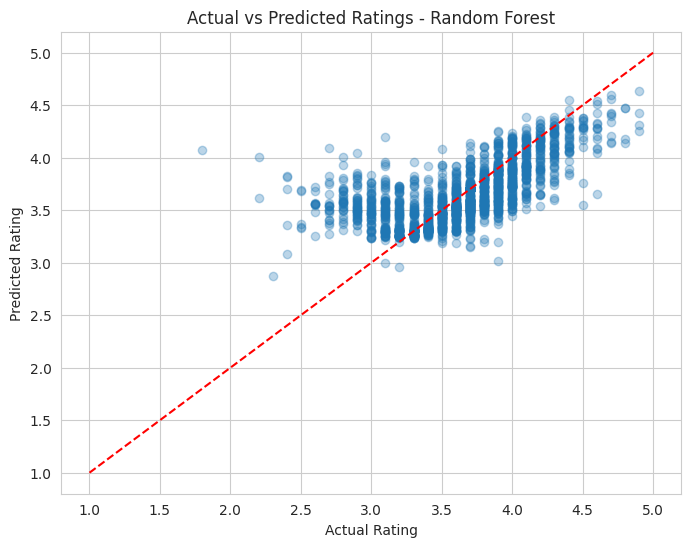

In [121]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.3
)

plt.plot(
    [1, 5],
    [1, 5],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")

plt.title(
    f"Actual vs Predicted Ratings - {best_model_name}"
)

plt.show()

In [122]:
import joblib

joblib.dump(
    best_model,
    "rating_prediction_model.pkl"
)

['rating_prediction_model.pkl']

In [123]:
import os

print(
    os.path.getsize(
        "rating_prediction_model.pkl"
    ),
    "bytes"
)

27760627 bytes


In [124]:
from google.colab import files

files.download(
    "rating_prediction_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [125]:
loaded_model = joblib.load(
    "rating_prediction_model.pkl"
)

test_prediction = loaded_model.predict(
    X_test.head(5)
)

print(test_prediction)

[3.37353309 3.64883896 3.8526304  3.7        3.32682525]
